# Analyse de la fraude financière – EDA

## 1. Importation des bibliothèques et configuration

In [1]:
from pathlib import Path
import warnings

import numpy as np # type: ignore 
import pandas as pd # type: ignore 
import matplotlib.pyplot as plt # type: ignore 
import seaborn as sns # type: ignore 

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

sns.set_theme(style="whitegrid", palette="deep")

## 2. Chargement des données

In [2]:
DATA_PATH = Path("../data/raw/PS_20174392719_1491204439457_log.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Fichier introuvable : {DATA_PATH.resolve()}\n"
        "Vérifiez le chemin du fichier CSV."
    )

df = pd.read_csv(DATA_PATH)

print(f"Dimensions du jeu de données : {df.shape[0]:,} lignes et {df.shape[1]} colonnes")
display(df.head())

Dimensions du jeu de données : 6,362,620 lignes et 11 colonnes


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.64",C1231006815,"170,136.00","160,296.36",M1979787155,0.00,0.00,0,0
1,1,PAYMENT,"1,864.28",C1666544295,"21,249.00","19,384.72",M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,"21,182.00",0.00,1,0
4,1,PAYMENT,"11,668.14",C2048537720,"41,554.00","29,885.86",M1230701703,0.00,0.00,0,0


## 3. Comprendre la structure du jeu de données

Cette étape permet de vérifier les colonnes disponibles, les types de données et le nombre de valeurs différentes.

- Une ligne représente une transaction.
- `type` indique la catégorie de transaction.
- `amount` représente le montant transféré.
- Les colonnes `oldbalance` et `newbalance` décrivent les soldes avant et après l'opération.
- `isFraud` indique si la transaction est frauduleuse.

In [3]:
display(pd.DataFrame({
    "type": df.dtypes.astype(str),
    "valeurs_distinctes": df.nunique(dropna=True),
    "valeurs_manquantes": df.isna().sum()
}).sort_index())

print("Noms des colonnes :")
print(df.columns.tolist())

,type,valeurs_distinctes,valeurs_manquantes
amount,float64,5316900,0
isFlaggedFraud,int64,2,0
isFraud,int64,2,0
nameDest,object,2722362,0
nameOrig,object,6353307,0
newbalanceDest,float64,3555499,0
newbalanceOrig,float64,2682586,0
oldbalanceDest,float64,3614697,0
oldbalanceOrg,float64,1845844,0
step,int64,743,0


Noms des colonnes :
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


## 4. Vérification de la qualité des données

In [4]:
# Vérifier les colonnes indispensables
required_columns = {
    "step", "type", "amount",
    "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest",
    "isFraud", "isFlaggedFraud",
    "nameOrig", "nameDest"
}

missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Colonnes indispensables absentes : {sorted(missing_columns)}")

# Valeurs manquantes
missing_summary = (
    df.isna().sum()
      .rename("nombre_manquant")
      .to_frame()
)

missing_summary["pourcentage"] = missing_summary["nombre_manquant"] / len(df) * 100
display(missing_summary.query("nombre_manquant > 0").sort_values("nombre_manquant", ascending=False))

,nombre_manquant,pourcentage


In [5]:
# Doublons
print(f"Nombre de lignes dupliquées : {df.duplicated().sum():,}")

Nombre de lignes dupliquées : 0


In [6]:
# Valeurs de la cible et du flag existant
print("Valeurs de isFraud :", sorted(df["isFraud"].dropna().unique()))
print("Valeurs de isFlaggedFraud :", sorted(df["isFlaggedFraud"].dropna().unique()))

Valeurs de isFraud : [0, 1]
Valeurs de isFlaggedFraud : [0, 1]


In [7]:
# Contrôles simples sur les valeurs numériques
numeric_cols = df.select_dtypes(include=np.number).columns
display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
step,"6,362,620.00",243.40,142.33,1.00,156.00,239.00,335.00,743.00
amount,"6,362,620.00","179,861.90","603,858.23",0.00,"13,389.57","74,871.94","208,721.48","92,445,516.64"
oldbalanceOrg,"6,362,620.00","833,883.10","2,888,242.67",0.00,0.00,"14,208.00","107,315.18","59,585,040.37"
newbalanceOrig,"6,362,620.00","855,113.67","2,924,048.50",0.00,0.00,0.00,"144,258.41","49,585,040.37"
oldbalanceDest,"6,362,620.00","1,100,701.67","3,399,180.11",0.00,0.00,"132,705.66","943,036.71","356,015,889.35"
newbalanceDest,"6,362,620.00","1,224,996.40","3,674,128.94",0.00,0.00,"214,661.44","1,111,909.25","356,179,278.92"
isFraud,"6,362,620.00",0.00,0.04,0.00,0.00,0.00,0.00,1.00
isFlaggedFraud,"6,362,620.00",0.00,0.00,0.00,0.00,0.00,0.00,1.00


- Des valeurs manquantes peuvent nécessiter un traitement avant la modélisation.
- Les doublons doivent être étudiés avant toute suppression.
- Les montants et les soldes doivent être non négatifs dans le contexte attendu.
- Il faut vérifier que `isFraud` contient bien uniquement les valeurs 0 et 1.

In [8]:
print("Valeurs négatives par variable numérique :")
display((df[numeric_cols] < 0).sum().sort_values(ascending=False).to_frame("nombre"))

print("Valeurs de la cible :")
display(df["isFraud"].value_counts(dropna=False).to_frame("effectif"))

Valeurs négatives par variable numérique :


,nombre
step,0
amount,0
oldbalanceOrg,0
newbalanceOrig,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0
isFlaggedFraud,0


Valeurs de la cible :


,effectif
isFraud,
0,6354407
1,8213


## 5. Analyse de la variable cible : `isFraud`

La première question est de mesurer la part des transactions frauduleuses dans le jeu de données.

Dans un problème de fraude, les transactions frauduleuses sont souvent beaucoup moins nombreuses que les transactions légitimes. Cette situation est appelée **déséquilibre des classes**.

Lorsque les classes sont déséquilibrées, l'accuracy seule peut donner une image trompeuse des performances d'un modèle.

,nombre,pourcentage
Transactions légitimes,6354407,99.87
Transactions frauduleuses,8213,0.13


C:\Users\hp\AppData\Local\Temp\ipykernel_13004\1358227184.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Légitime (0)", "Frauduleuse (1)"])


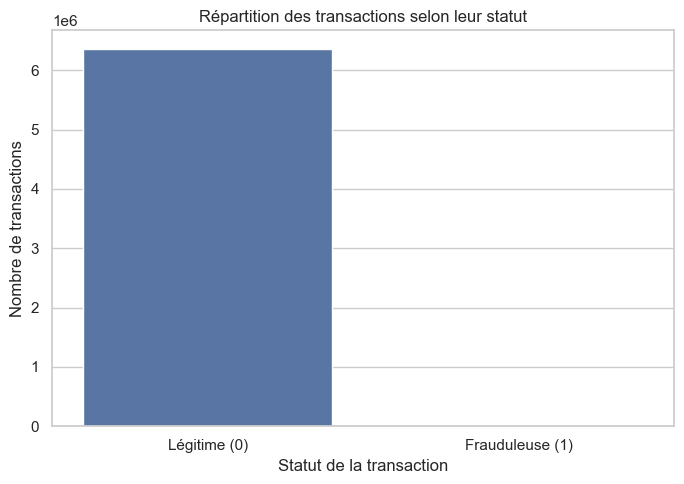

In [9]:
target_counts = df["isFraud"].value_counts().reindex([0, 1], fill_value=0)
target_percentages = df["isFraud"].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100

target_summary = pd.DataFrame({
    "nombre": target_counts,
    "pourcentage": target_percentages
})
target_summary.index = ["Transactions légitimes", "Transactions frauduleuses"]
display(target_summary.round(4))

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x="isFraud", order=[0, 1])
ax.set_xticklabels(["Légitime (0)", "Frauduleuse (1)"])
ax.set_title("Répartition des transactions selon leur statut")
ax.set_xlabel("Statut de la transaction")
ax.set_ylabel("Nombre de transactions")
plt.tight_layout()
plt.show()

## 6. Analyse des types de transactions

Cette partie répond à deux questions :

1. Quels types de transactions sont les plus fréquents ?
2. Pour chaque type, quelle proportion des transactions est frauduleuse ?

Il faut distinguer le **nombre de fraudes** du **taux de fraude**. Un type peut avoir beaucoup de fraudes simplement parce qu'il contient beaucoup de transactions.

,nombre_transactions
type,
CASH_OUT,2237500
PAYMENT,2151495
CASH_IN,1399284
TRANSFER,532909
DEBIT,41432


,nombre_transactions,nombre_fraudes,taux_fraude,taux_fraude_pct
type,,,,
TRANSFER,532909,4097,0.01,0.77
CASH_OUT,2237500,4116,0.00,0.18
CASH_IN,1399284,0,0.00,0.00
DEBIT,41432,0,0.00,0.00
PAYMENT,2151495,0,0.00,0.00


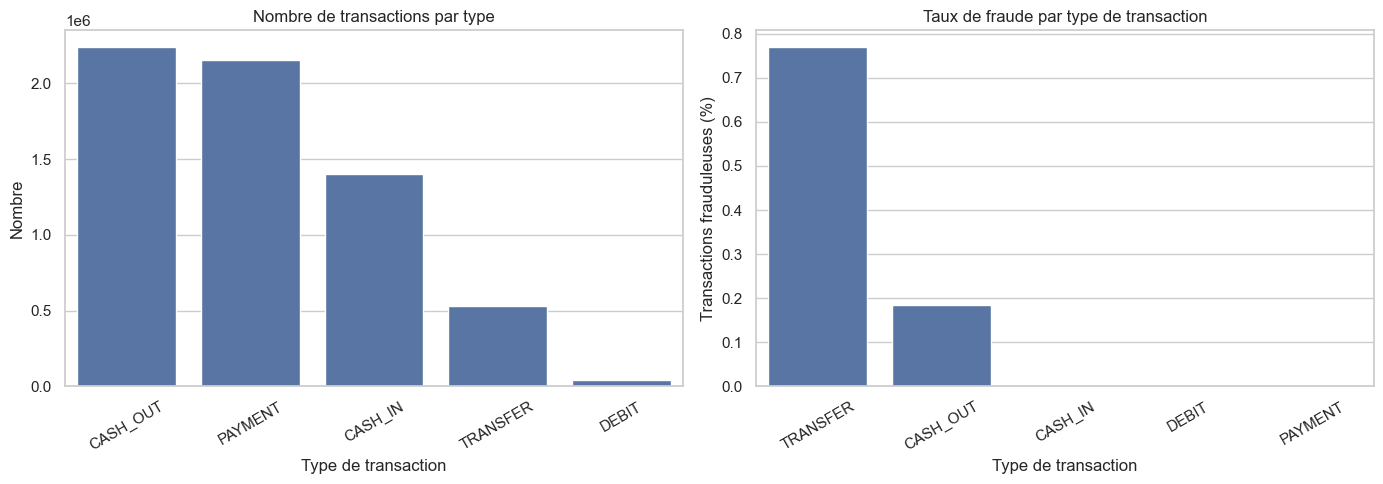

In [10]:
type_counts = df["type"].value_counts().rename("nombre_transactions").to_frame()
display(type_counts)

type_analysis = (
    df.groupby("type", dropna=False)["isFraud"]
      .agg(nombre_transactions="size", nombre_fraudes="sum", taux_fraude="mean")
)
type_analysis["taux_fraude_pct"] = type_analysis["taux_fraude"] * 100
type_analysis = type_analysis.sort_values("taux_fraude_pct", ascending=False)
display(type_analysis.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="type", order=df["type"].value_counts().index, ax=axes[0])
axes[0].set_title("Nombre de transactions par type")
axes[0].set_xlabel("Type de transaction")
axes[0].set_ylabel("Nombre")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=type_analysis.reset_index(),
    x="type", y="taux_fraude_pct", ax=axes[1]
)
axes[1].set_title("Taux de fraude par type de transaction")
axes[1].set_xlabel("Type de transaction")
axes[1].set_ylabel("Transactions frauduleuses (%)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

**Interprétation :** repérez les types qui présentent les taux de fraude les plus élevés, puis vérifiez leur nombre de transactions. Une proportion élevée calculée sur très peu de transactions doit être interprétée avec prudence.

## 7. Analyse des montants des transactions

Les montants peuvent être différents selon que la transaction est frauduleuse ou légitime.

On compare ici :
- le nombre de transactions ;
- la moyenne et la médiane des montants ;
- les quartiles et les valeurs extrêmes ;
- la distribution des montants selon le statut de fraude.

La médiane est utile lorsque quelques transactions ont des montants très élevés.

,count,mean,median,std,min,max
Légitime,6354407,"178,197.04","74,684.72","596,236.98",0.01,"92,445,516.64"
Frauduleuse,8213,"1,467,967.30","441,423.44","2,404,252.95",0.00,"10,000,000.00"


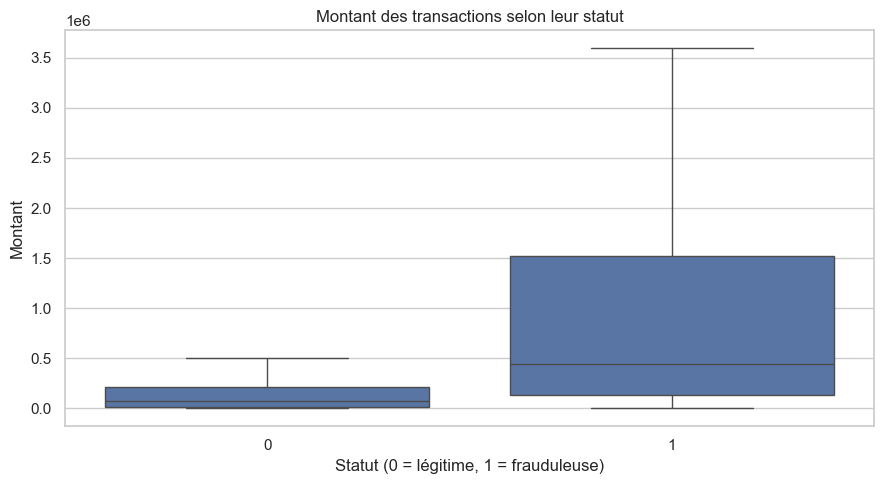

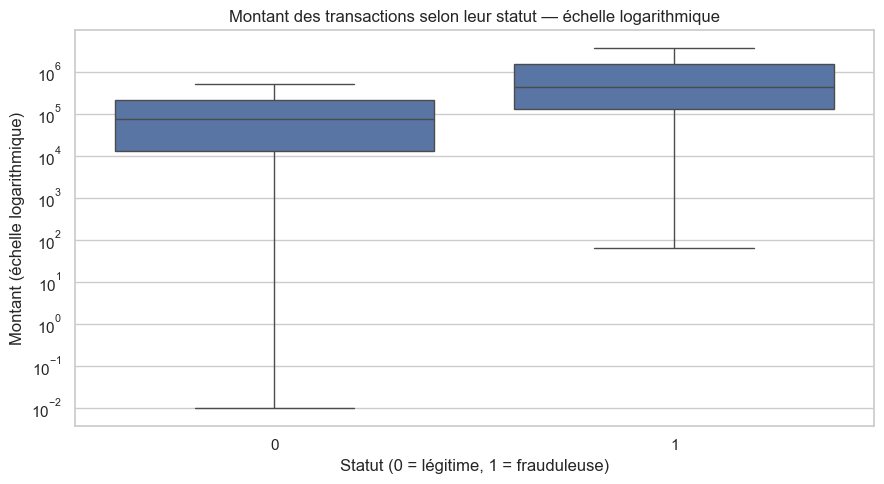

In [11]:
amount_summary = (
    df.groupby("isFraud")["amount"]
      .agg(["count", "mean", "median", "std", "min", "max"])
)
amount_summary.index = ["Légitime", "Frauduleuse"]
display(amount_summary.round(2))

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="isFraud", y="amount", showfliers=False)
plt.title("Montant des transactions selon leur statut")
plt.xlabel("Statut (0 = légitime, 1 = frauduleuse)")
plt.ylabel("Montant")
plt.tight_layout()
plt.show()

# Échelle logarithmique pour mieux visualiser les montants très dispersés.
positive_amounts = df.loc[df["amount"] > 0].copy()
plt.figure(figsize=(9, 5))
sns.boxplot(data=positive_amounts, x="isFraud", y="amount", showfliers=False)
plt.yscale("log")
plt.title("Montant des transactions selon leur statut — échelle logarithmique")
plt.xlabel("Statut (0 = légitime, 1 = frauduleuse)")
plt.ylabel("Montant (échelle logarithmique)")
plt.tight_layout()
plt.show()

### Montants selon le type de transaction

Comparer les montants à l'intérieur de chaque type permet d'éviter de mélanger des opérations qui n'ont pas le même comportement.

In [12]:
amount_by_type_fraud = (
    df.groupby(["type", "isFraud"])["amount"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)
display(amount_by_type_fraud)

count         mean     median   min           max
type     isFraud                                                     
CASH_IN  0        1399284   168,920.24 143,427.71  0.04  1,915,267.90
CASH_OUT 0        2233384   173,917.16 146,946.56  0.01  2,847,566.62
         1           4116 1,455,102.59 435,516.90  0.00 10,000,000.00
DEBIT    0          41432     5,483.67   3,048.99  0.55    569,077.51
PAYMENT  0        2151495    13,057.60   9,482.19  0.02    238,637.98
TRANSFER 0         528812   906,229.01 486,521.91  2.60 92,445,516.64
         1           4097 1,480,891.67 445,705.76 63.80 10,000,000.00

**Interprétation :** comparez surtout les médianes et les distributions des montants pour les transactions légitimes et frauduleuses d'un même type. Ne concluez pas qu'un montant élevé indique automatiquement une fraude.

## 8. Analyse des soldes des comptes

Les colonnes de solde décrivent la situation des comptes avant et après la transaction :

- `oldbalanceOrg` : solde du compte d'origine avant l'opération ;
- `newbalanceOrig` : solde du compte d'origine après l'opération ;
- `oldbalanceDest` : solde du compte destinataire avant l'opération ;
- `newbalanceDest` : solde du compte destinataire après l'opération.

On compare les soldes entre les deux catégories de transactions.

,Légitime,Frauduleuse
oldbalanceOrg,"14,069.00","438,983.45"
newbalanceOrig,0.00,0.00
oldbalanceDest,"133,311.80",0.00
newbalanceDest,"214,881.70","4,676.42"


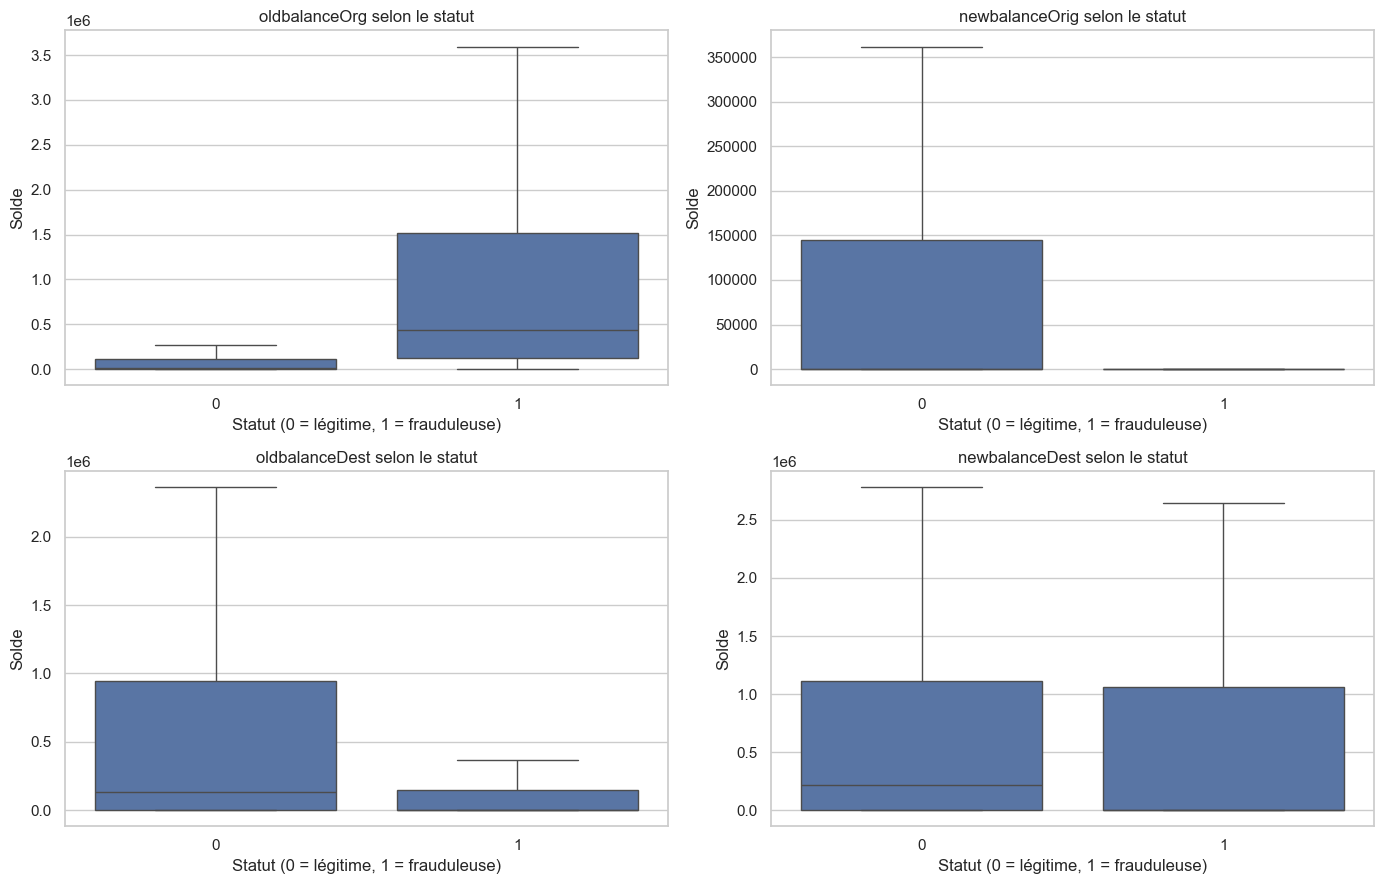

In [13]:
balance_columns = [
    "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest"
]

balance_summary = df.groupby("isFraud")[balance_columns].median().T
balance_summary.columns = ["Légitime", "Frauduleuse"]
display(balance_summary.round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for column, ax in zip(balance_columns, axes.flat):
    sns.boxplot(data=df, x="isFraud", y=column, showfliers=False, ax=ax)
    ax.set_title(f"{column} selon le statut")
    ax.set_xlabel("Statut (0 = légitime, 1 = frauduleuse)")
    ax.set_ylabel("Solde")

plt.tight_layout()
plt.show()

## 9. Évolution des soldes et cohérence des opérations

On calcule les changements de solde à partir des valeurs avant et après chaque transaction.

- Variation du compte d'origine = solde avant − solde après.
- Variation du compte destinataire = solde après − solde avant.

On calcule aussi des écarts entre le montant de la transaction et les variations de solde. Ces écarts peuvent révéler des comportements différents, mais ils ne prouvent pas à eux seuls une fraude.

In [14]:
eda_df = df.copy()

eda_df["origin_balance_change"] = (
    eda_df["oldbalanceOrg"] - eda_df["newbalanceOrig"]
)
eda_df["destination_balance_change"] = (
    eda_df["newbalanceDest"] - eda_df["oldbalanceDest"]
)

eda_df["origin_balance_error"] = (
    eda_df["oldbalanceOrg"] - eda_df["amount"] - eda_df["newbalanceOrig"]
)
eda_df["destination_balance_error"] = (
    eda_df["oldbalanceDest"] + eda_df["amount"] - eda_df["newbalanceDest"]
)

derived_columns = [
    "origin_balance_change", "destination_balance_change",
    "origin_balance_error", "destination_balance_error"
]

display(
    eda_df.groupby("isFraud")[derived_columns]
          .agg(["mean", "median", "std"])
          .round(2)
)

origin_balance_change                          \
                         mean     median          std   
isFraud                                                 
0                  -23,141.52       0.00   106,223.30   
1                1,457,274.97 436,317.49 2,396,099.20   

        destination_balance_change                     origin_balance_error  \
                              mean median          std                 mean   
isFraud                                                                       
0                       123,504.81   0.00   810,422.27          -201,338.56   
1                       735,458.00   0.00 1,856,983.86           -10,692.33   

                              destination_balance_error                        
            median        std                      mean   median          std  
isFraud                                                                        
0       -69,049.31 606,928.89                 54,692.23 3,500.68   436,002.63  
1             0.00 265,146.13                732,509.30 2,231.46 1,867,747.99

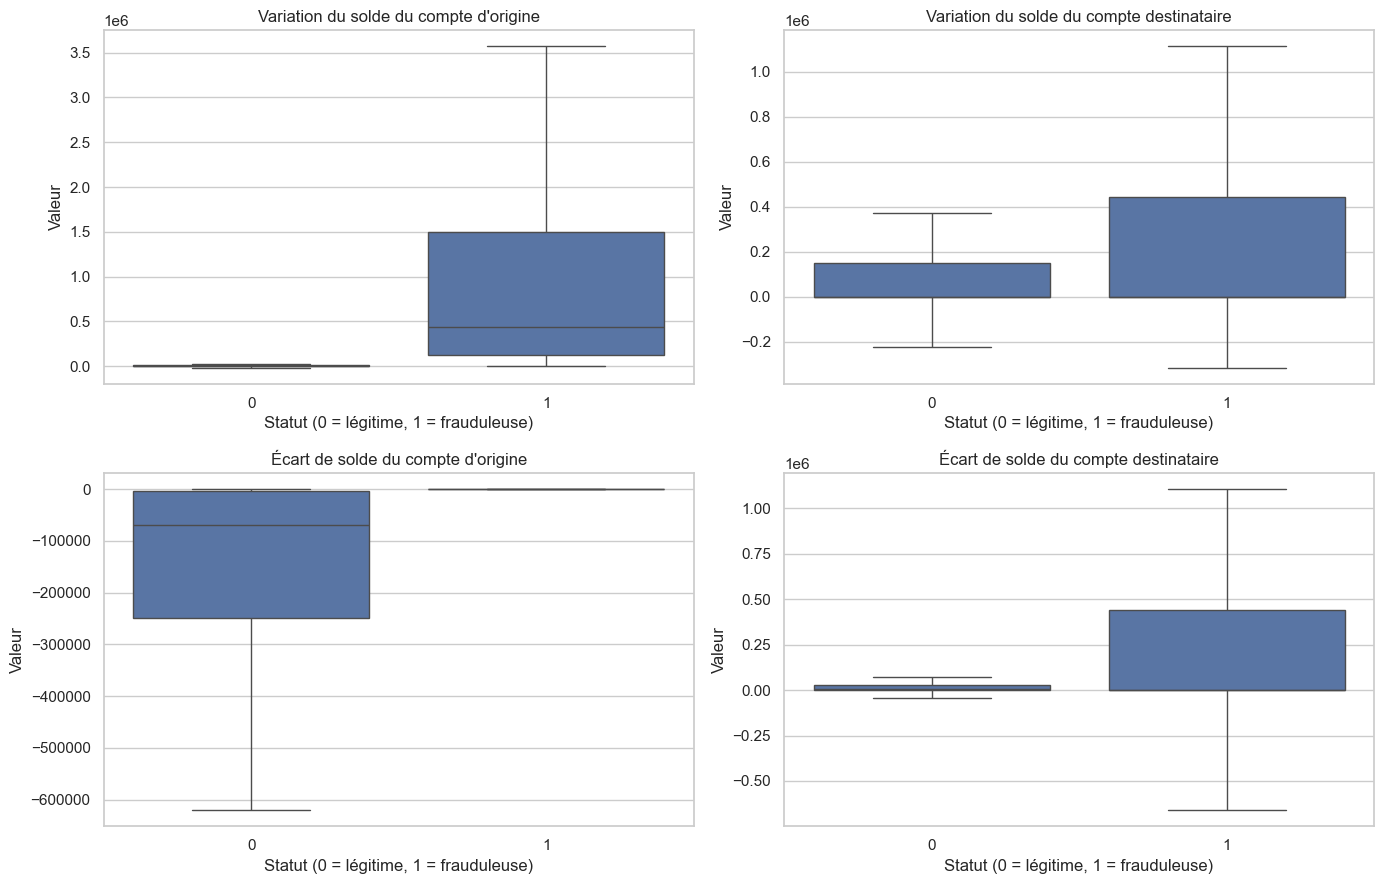

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

plot_columns = [
    ("origin_balance_change", "Variation du solde du compte d'origine"),
    ("destination_balance_change", "Variation du solde du compte destinataire"),
    ("origin_balance_error", "Écart de solde du compte d'origine"),
    ("destination_balance_error", "Écart de solde du compte destinataire")
]

for (column, title), ax in zip(plot_columns, axes.flat):
    sns.boxplot(data=eda_df, x="isFraud", y=column, showfliers=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Statut (0 = légitime, 1 = frauduleuse)")
    ax.set_ylabel("Valeur")

plt.tight_layout()
plt.show()

**Attention :** dans les jeux de données de type PaySim, les soldes simulés ne suivent pas toujours une règle comptable parfaite. Les écarts calculés doivent donc être étudiés comme des caractéristiques possibles, et non comme une preuve directe de fraude.

## 10. Analyse de la variable `isFlaggedFraud`

`isFlaggedFraud` est un indicateur déjà présent dans le jeu de données. Il ne faut pas le confondre avec la variable cible `isFraud`.

On vérifie :
- combien de transactions sont signalées par cet indicateur ;
- combien de ces transactions sont réellement frauduleuses selon `isFraud` ;
- si cet indicateur couvre une grande partie des fraudes.

**Précaution pour la modélisation :** cet indicateur peut provenir d'une règle de détection déjà existante. Il faut donc vérifier sa définition et son moment de disponibilité. Pour éviter une fuite d'information, il est préférable de ne pas l'utiliser comme variable prédictive dans le premier modèle.

In [16]:
flag_counts = pd.crosstab(
    df["isFraud"], df["isFlaggedFraud"],
    rownames=["Statut réel"], colnames=["Transaction signalée"]
)
display(flag_counts)

flag_by_target = (
    pd.crosstab(df["isFraud"], df["isFlaggedFraud"], normalize="index") * 100
)
display(flag_by_target.round(4))

print("Nombre de transactions signalées :", int(df["isFlaggedFraud"].sum()))

Transaction signalée,0,1
Statut réel,,
0,6354407,0
1,8197,16


isFlaggedFraud,0,1
isFraud,,
0,100.00,0.00
1,99.81,0.19


Nombre de transactions signalées : 16


## 11. Analyse de la variable temporelle `step`

`step` est un index temporel entier fourni par le jeu de données. Il ne doit pas être présenté comme une date réelle sans connaître précisément sa définition.

On observe le nombre de transactions et le taux de fraude à chaque étape.

Valeur minimale de step : 1
Valeur maximale de step : 743
Nombre de valeurs distinctes : 743


,nombre_transactions,nombre_fraudes,taux_fraude,taux_fraude_pct
step,,,,
1,2708,16,0.01,0.59
2,1014,8,0.01,0.79
3,552,4,0.01,0.72
4,565,10,0.02,1.77
5,665,6,0.01,0.90


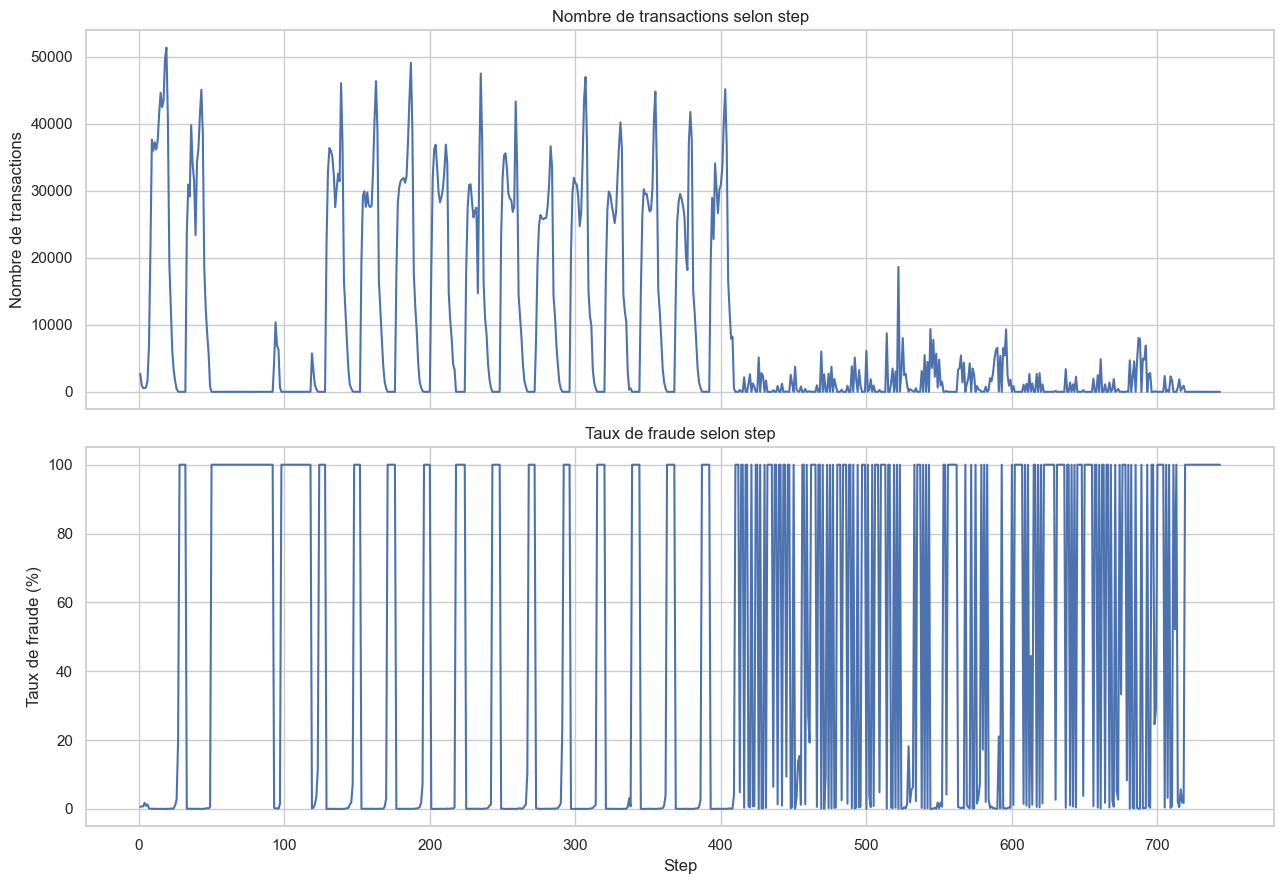

In [17]:
print(f"Valeur minimale de step : {df['step'].min()}")
print(f"Valeur maximale de step : {df['step'].max()}")
print(f"Nombre de valeurs distinctes : {df['step'].nunique()}")

step_analysis = (
    df.groupby("step")["isFraud"]
      .agg(nombre_transactions="size", nombre_fraudes="sum", taux_fraude="mean")
)
step_analysis["taux_fraude_pct"] = step_analysis["taux_fraude"] * 100
display(step_analysis.head())

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

sns.lineplot(data=step_analysis, x=step_analysis.index, y="nombre_transactions", ax=axes[0])
axes[0].set_title("Nombre de transactions selon step")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Nombre de transactions")

sns.lineplot(data=step_analysis, x=step_analysis.index, y="taux_fraude_pct", ax=axes[1])
axes[1].set_title("Taux de fraude selon step")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Taux de fraude (%)")

plt.tight_layout()
plt.show()

**Interprétation :** recherchez les périodes où le nombre de transactions ou le taux de fraude change. Un taux calculé sur une période avec très peu de transactions peut être instable. Il faut donc toujours regarder le volume associé.

## 12. Analyse des comptes d'origine et de destination

Les identifiants `nameOrig` et `nameDest` identifient les comptes. Ils ne doivent pas être utilisés directement comme variables numériques dans un modèle classique.

On examine d'abord les préfixes des identifiants, puis le nombre de transactions et de fraudes associés aux comptes. Cette analyse peut aider à comprendre la structure des données, mais les identifiants peuvent être spécifiques à la simulation.

In [18]:
eda_df["origin_prefix"] = eda_df["nameOrig"].astype("string").str[0]
eda_df["destination_prefix"] = eda_df["nameDest"].astype("string").str[0]

print("Préfixes des comptes d'origine :")
display(eda_df["origin_prefix"].value_counts(dropna=False).to_frame("nombre"))

print("Préfixes des comptes destinataires :")
display(eda_df["destination_prefix"].value_counts(dropna=False).to_frame("nombre"))

origin_prefix_analysis = (
    eda_df.groupby("origin_prefix")["isFraud"]
          .agg(nombre_transactions="size", nombre_fraudes="sum", taux_fraude="mean")
)
origin_prefix_analysis["taux_fraude_pct"] = origin_prefix_analysis["taux_fraude"] * 100

destination_prefix_analysis = (
    eda_df.groupby("destination_prefix")["isFraud"]
          .agg(nombre_transactions="size", nombre_fraudes="sum", taux_fraude="mean")
)
destination_prefix_analysis["taux_fraude_pct"] = destination_prefix_analysis["taux_fraude"] * 100

display(origin_prefix_analysis.round(4))
display(destination_prefix_analysis.round(4))

Préfixes des comptes d'origine :


,nombre
origin_prefix,
C,6362620


Préfixes des comptes destinataires :


,nombre
destination_prefix,
C,4211125
M,2151495


,nombre_transactions,nombre_fraudes,taux_fraude,taux_fraude_pct
origin_prefix,,,,
C,6362620,8213,0.00,0.13


,nombre_transactions,nombre_fraudes,taux_fraude,taux_fraude_pct
destination_prefix,,,,
C,4211125,8213,0.00,0.20
M,2151495,0,0.00,0.00


### Comptes qui apparaissent le plus souvent

Cette analyse permet de repérer les comptes très actifs et de vérifier s'ils sont associés à des transactions frauduleuses. Elle ne doit pas servir à conclure qu'un compte est frauduleux uniquement à partir de son identifiant.

In [19]:
origin_activity = (
    eda_df.groupby("nameOrig")
          .agg(
              nombre_transactions=("isFraud", "size"),
              nombre_fraudes=("isFraud", "sum")
          )
          .sort_values("nombre_transactions", ascending=False)
)
display(origin_activity.head(10))

destination_activity = (
    eda_df.groupby("nameDest")
          .agg(
              nombre_transactions=("isFraud", "size"),
              nombre_fraudes=("isFraud", "sum")
          )
          .sort_values("nombre_transactions", ascending=False)
)
display(destination_activity.head(10))

,nombre_transactions,nombre_fraudes
nameOrig,,
C1065307291,3,0
C1784010646,3,0
C1902386530,3,0
C1832548028,3,0
C545315117,3,0
C1462946854,3,0
C2051359467,3,0
C363736674,3,0
C1976208114,3,0


,nombre_transactions,nombre_fraudes
nameDest,,
C1286084959,113,0
C985934102,109,0
C665576141,105,0
C2083562754,102,0
C248609774,101,0
C1590550415,101,0
C1789550256,99,0
C451111351,99,0
C1360767589,98,0


## 13. Analyse croisée : type et montant

Cette analyse compare les montants des transactions frauduleuses et légitimes à l'intérieur de chaque type. Elle permet de voir si les différences observées sur l'ensemble du jeu de données sont liées au type de transaction.

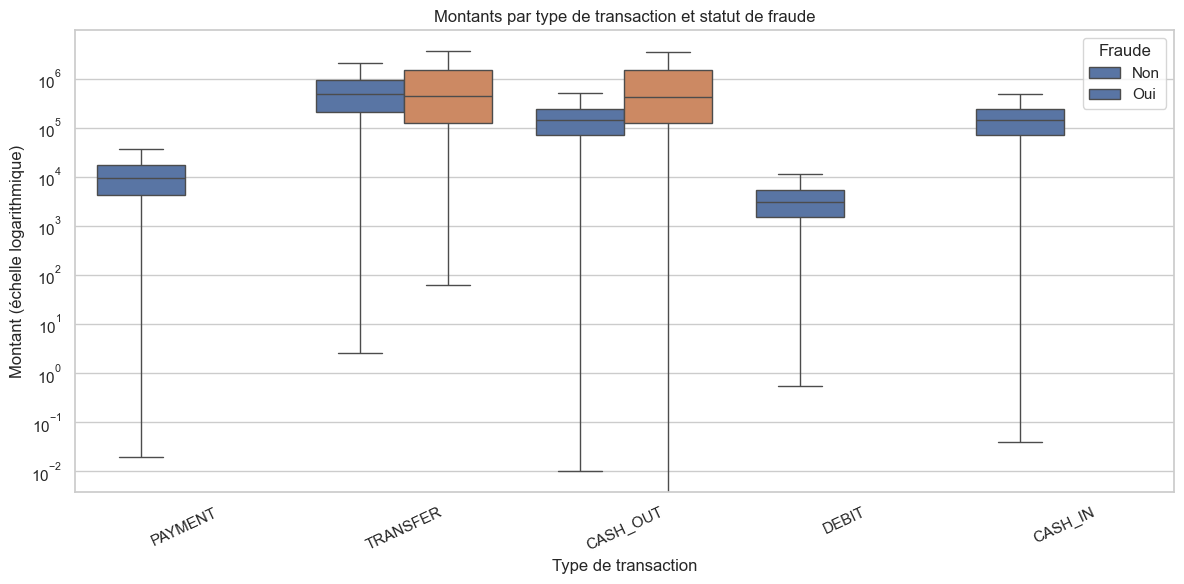

In [20]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=eda_df,
    x="type",
    y="amount",
    hue="isFraud",
    showfliers=False
)
plt.yscale("log")
plt.title("Montants par type de transaction et statut de fraude")
plt.xlabel("Type de transaction")
plt.ylabel("Montant (échelle logarithmique)")
plt.legend(title="Fraude", labels=["Non", "Oui"])
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 14. Analyse des corrélations numériques

La corrélation mesure une relation linéaire entre deux variables numériques. Elle ne prouve pas qu'une variable cause une fraude.

On étudie les corrélations entre les variables numériques et on affiche séparément leur corrélation avec `isFraud`. Les identifiants de comptes ne sont pas inclus dans cette analyse.

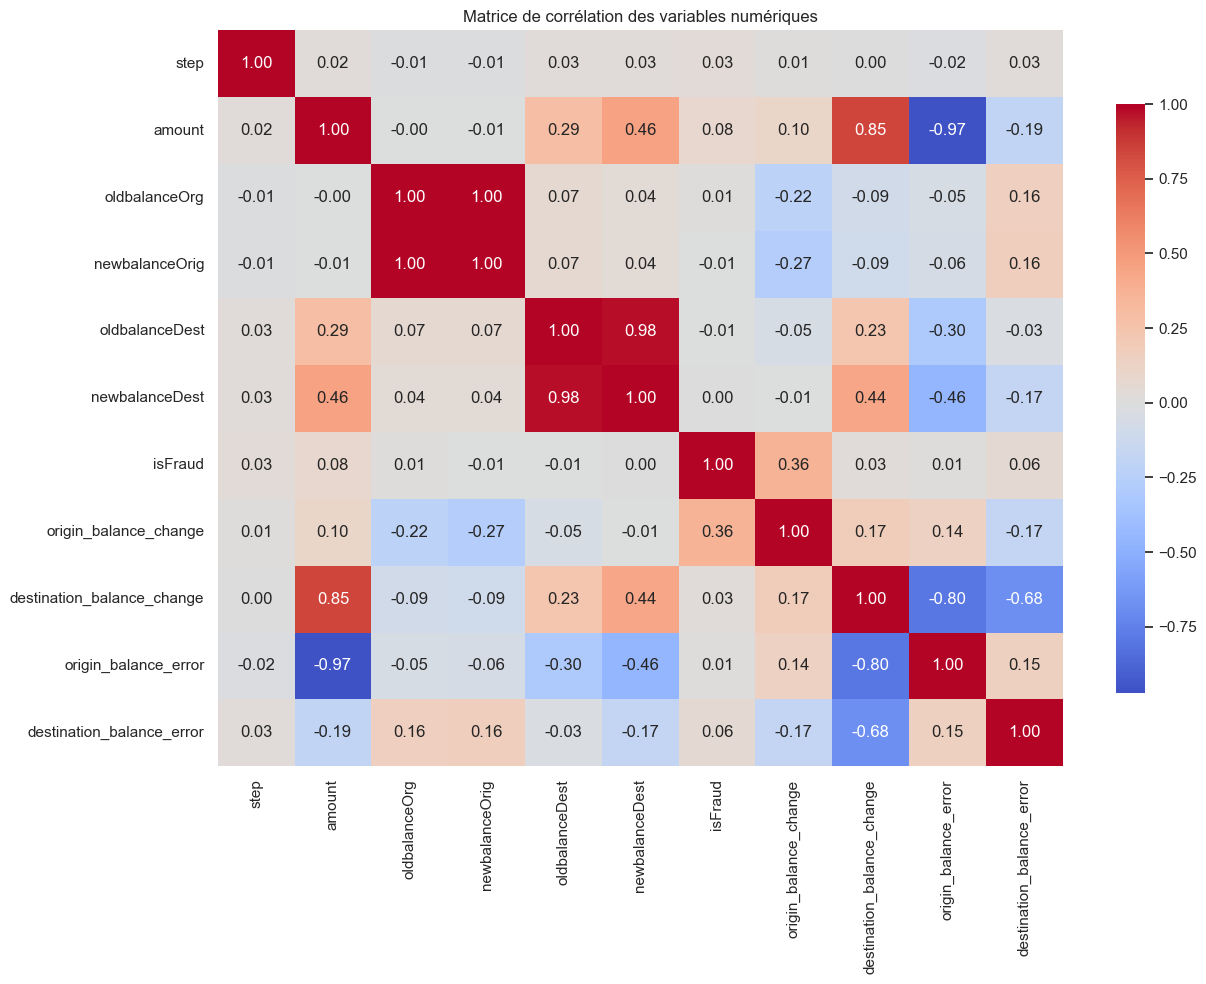

In [21]:
correlation_columns = [
    column for column in eda_df.select_dtypes(include=np.number).columns
    if column not in ["isFlaggedFraud"]
]

correlation = eda_df[correlation_columns].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    square=False,
    cbar_kws={"shrink": 0.8}
)
plt.title("Matrice de corrélation des variables numériques")
plt.tight_layout()
plt.show()

**Limite :** une corrélation faible n'exclut pas une relation non linéaire. Une corrélation élevée ne garantit pas non plus qu'une variable sera utile pour prédire de nouvelles fraudes.

## 15. Synthèse automatique de l'EDA

In [22]:
n_rows = len(eda_df)
n_fraud = int(eda_df["isFraud"].sum())
n_legitimate = n_rows - n_fraud
fraud_rate = eda_df["isFraud"].mean() * 100

summary = pd.DataFrame({
    "Indicateur": [
        "Nombre total de transactions",
        "Transactions légitimes",
        "Transactions frauduleuses",
        "Taux de fraude",
        "Nombre de types de transactions",
        "Valeurs manquantes",
        "Lignes dupliquées",
        "Nombre de steps distincts"
    ],
    "Valeur": [
        f"{n_rows:,}",
        f"{n_legitimate:,}",
        f"{n_fraud:,}",
        f"{fraud_rate:.4f} %",
        f"{eda_df['type'].nunique():,}",
        f"{eda_df.isna().sum().sum():,}",
        f"{eda_df.duplicated().sum():,}",
        f"{eda_df['step'].nunique():,}"
    ]
})
display(summary)

,Indicateur,Valeur
0,Nombre total de transactions,"6,362,620"
1,Transactions légitimes,"6,354,407"
2,Transactions frauduleuses,"8,213"
3,Taux de fraude,0.1291 %
4,Nombre de types de transactions,5
5,Valeurs manquantes,0
6,Lignes dupliquées,0
7,Nombre de steps distincts,743
